Using Colab cache for faster access to the 'iris' dataset.
Path to dataset files: /kaggle/input/iris

First 5 rows of Kaggle Dataset:
   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa


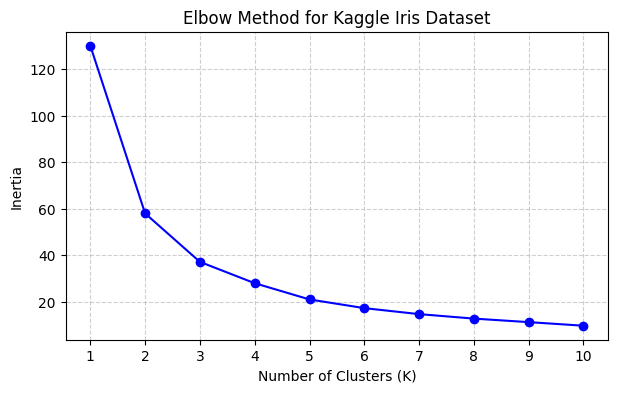


Dataset with assigned clusters:
   SepalLengthCm  SepalWidthCm      Species  Cluster
0            5.1           3.5  Iris-setosa        2
1            4.9           3.0  Iris-setosa        2
2            4.7           3.2  Iris-setosa        2
3            4.6           3.1  Iris-setosa        2
4            5.0           3.6  Iris-setosa        2


In [ ]:
import os
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# 1. Download dataset directly from Kaggle
# Example: Downloading the popular "Iris Species" dataset from Kaggle
path = kagglehub.dataset_download("uciml/iris")

print("Path to dataset files:", path)

# 2. Load the CSV file into Pandas
csv_file = os.path.join(path, "Iris.csv")
df = pd.read_csv(csv_file)

print("\nFirst 5 rows of Kaggle Dataset:")
print(df.head())

# 3. Extract features for K-Means Clustering
# Selecting 'SepalLengthCm' and 'SepalWidthCm'
X = df[['SepalLengthCm', 'SepalWidthCm']].values

# 4. Apply the Elbow Method to find optimal K
inertias = []
K_range = range(1, 11)

for k in K_range:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X)
    inertias.append(model.inertia_)

# 5. Plot the Elbow Curve
plt.figure(figsize=(7, 4))
plt.plot(K_range, inertias, marker='o', color='b')
plt.title("Elbow Method for Kaggle Iris Dataset")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(K_range)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# 6. Fit final model with K = 3
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X)

print("\nDataset with assigned clusters:")
print(df[['SepalLengthCm', 'SepalWidthCm', 'Species', 'Cluster']].head())

Dataset shape: (178, 2)
Selected features: Alcohol vs. Malic Acid



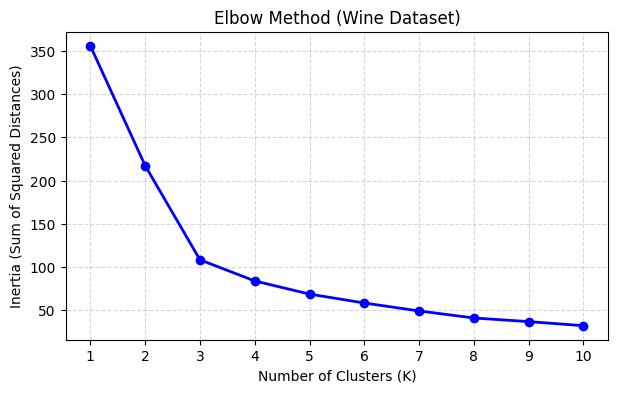

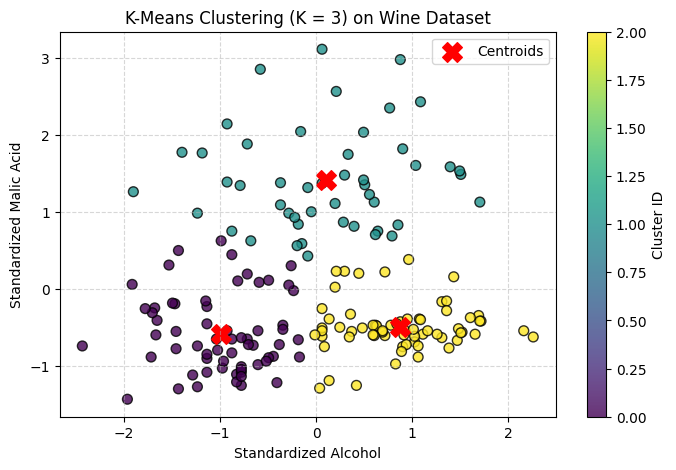

First 10 data points and their assigned clusters:
   alcohol  malic_acid  Cluster
0    14.23        1.71        2
1    13.20        1.78        2
2    13.16        2.36        2
3    14.37        1.95        2
4    13.24        2.59        2
5    14.20        1.76        2
6    14.39        1.87        2
7    14.06        2.15        2
8    14.83        1.64        2
9    13.86        1.35        2


In [ ]:
# K-Means Clustering on Wine Dataset

# Step 1: Import required libraries
import os
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler

# Step 2: Load the Wine dataset
wine = load_wine()
df = pd.DataFrame(wine.data, columns=wine.feature_names)

# Select 2 features for 2D visualization: Alcohol and Malic Acid
X = df[['alcohol', 'malic_acid']].values

print("Dataset shape:", X.shape)
print("Selected features: Alcohol vs. Malic Acid\n")

# Step 3: Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 4: Apply the Elbow Method to find optimal K
inertia = []
K_range = range(1, 11)

for k in K_range:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertia.append(model.inertia_)

# Step 5: Plot the Elbow graph
plt.figure(figsize=(7, 4))
plt.plot(K_range, inertia, marker='o', color='b', linewidth=2)
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia (Sum of Squared Distances)")
plt.title("Elbow Method (Wine Dataset)")
plt.xticks(K_range)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Step 6: Apply K-Means with K = 3
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)
df['Cluster'] = clusters

# Step 7: Visualize the clusters and centroids
plt.figure(figsize=(8, 5))

# Scatter plot for clustered data points
scatter = plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=clusters,
    cmap='viridis',
    s=50,
    alpha=0.8,
    edgecolor='k',
)

# Plot cluster centroids
plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    marker='X',
    s=200,
    color='red',
    label='Centroids',
)

plt.xlabel("Standardized Alcohol")
plt.ylabel("Standardized Malic Acid")
plt.title("K-Means Clustering (K = 3) on Wine Dataset")
plt.legend()
plt.colorbar(scatter, label='Cluster ID')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Step 8: Display cluster assignments
print("First 10 data points and their assigned clusters:")
print(
    df[['alcohol', 'malic_acid', 'Cluster']]
    .head(10)
    .to_string(index=True)
)